# SensEscada — Dynamic Programming
## Challenge Motiva + FIAP 2026/2027 · Sprint 1 e 2

**Squad SensEscada** — Felipe Estevo Santos (RM567780) · Igor Grave Teixeira (RM567663) · Renan dos Reis Santos (RM568540)

Este notebook executa, do início ao fim, as três entregas da disciplina:
1. **Degradação acumulada** de cada escada: versões recursiva pura, memoizada (dicionário) e iterativa (tabulação), com medição e **ranking por criticidade**;
2. **Rede de estações como grafo** (lista de adjacência): **BFS** (menos trechos), **Dijkstra** (menor tempo), reconstrução das rotas e **A\*** com heurística justificada;
3. **`planejar_turno(base, horas)`**: quais escadas atender no turno, em que ordem e por qual caminho.

O código das funções está em `src/` (documentado com docstrings). Este notebook só chama as funções e interpreta os resultados.

### Dados utilizados (`data/`)
| Arquivo | Conteúdo | Origem |
|---|---|---|
| `leituras_mensais_sensores.csv` | 1 linha por escada × mês (jan/2023–set/2026): ocorrências em cada uma das 5 famílias de sinal (vibração, temperatura, corrente/tensão, óleo, velocidade) + horas paradas | gerado do **dataset real da Motiva** (histórico SAP de manutenção da ViaQuatro) no notebook de EDA |
| `cadastro_escadas.csv` | escada → estação + tempo típico de atendimento | idem |
| `parametros_degradacao.json` | α, β (ajuste AR(2) da série real) e peso de cada família | idem |
| `rede_estacoes.json` | 12 estações/terminal da Linha 4-Amarela + 1 base de manutenção, 34 trechos com minutos | `scripts/gerar_rede.py` |

> **Sobre o dataset:** a Motiva entregou o histórico de manutenção (notas de falha, mão de obra e material), não leituras contínuas de sensor.
> Na EDA, cada falha real foi classificada pela família de sinal que poderia detectá-la; a "leitura" mensal de cada família é o nº de ocorrências
> daquela família no mês. Assim, todo o cálculo abaixo usa **dados reais** e fica pronto para receber leituras de sensores quando existirem (basta trocar o CSV).

In [1]:
import sys, time, json, math, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from src import dados, degradacao as dg, grafo
from src.planejamento import planejar_turno

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.titleweight": "bold"})
COR = {"rec": "#d1495b", "memo": "#3b2fc9", "tab": "#00a6c8", "neutra": "#8a8fa3"}

leituras = dados.carregar_leituras()
cadastro = dados.carregar_cadastro()
param = dados.carregar_parametros()
ALFA, BETA, PESOS = param["alfa"], param["beta"], param["pesos_familias"]
rede = grafo.carregar_rede(dados.PASTA_DADOS / "rede_estacoes.json")
print(f"{len(leituras)} escadas | {len(next(iter(leituras.values())))} leituras mensais por escada | α = {ALFA} | β = {BETA}")
print("Pesos por família:", PESOS)
pd.read_csv(dados.PASTA_DADOS / "leituras_mensais_sensores.csv").head()

201 escadas | 45 leituras mensais por escada | α = 0.281 | β = 0.17
Pesos por família: {'corrente_tensao': 0.722, 'oleo': 0.241, 'temperatura': 1.333, 'velocidade': 0.341, 'vibracao': 2.363}


,escada,estacao,mes,vibracao,temperatura,corrente_tensao,oleo,velocidade,horas_paradas
0,BUT-ER01,BUT,2023-01,1,0,0,0,0,18.05
1,BUT-ER01,BUT,2023-02,0,0,0,0,0,0.00
2,BUT-ER01,BUT,2023-03,0,0,0,0,0,1.24
3,BUT-ER01,BUT,2023-04,0,0,0,0,0,7.46
4,BUT-ER01,BUT,2023-05,1,0,1,0,0,54.45


## 1. Degradação acumulada
### 1.1 Modelo
**Severidade do mês** (combinação dos cinco sinais):  $s(t) = \sum_f w_f \cdot x_f(t)$

**Degradação acumulada** (memória de dois meses):  $D(t) = s(t) + \alpha \cdot D(t-1) + \beta \cdot D(t-2)$, com $D(-1) = D(-2) = 0$.

Por que esse modelo (justificativa baseada nos dados da EDA):
- **pesos $w_f$**: duração média de indisponibilidade de cada família ÷ média das cinco. Uma ocorrência de vibração (redutor, eixo, corrente principal)
  deixa a escada parada, em média, ~10 vezes mais que uma de óleo, então pesa mais;
- **α e β**: a série mensal real de falhas tem autocorrelação significativa nos lags 1 e 2. O ajuste AR(2) dá α ≈ 0,28 e β ≈ 0,17;
  como α + β < 1, eventos antigos perdem peso e a degradação reflete a **condição recente**;
- **duas parcelas recursivas** (t−1 e t−2) criam **subproblemas sobrepostos**, exatamente a estrutura em que a programação dinâmica faz diferença.

In [2]:
pesos_df = pd.DataFrame({"peso w_f": PESOS}).sort_values("peso w_f", ascending=False)
pesos_df["interpretação"] = ["falhas mecânicas longas (redutor/eixo/corrente)", "desarme térmico do motor", "inversor/contator/disjuntor",
                             "sensor/controlador de velocidade", "lubrificação"][:len(pesos_df)]
pesos_df

,peso w_f,interpretação
vibracao,2.363,falhas mecânicas longas (redutor/eixo/corrente)
temperatura,1.333,desarme térmico do motor
corrente_tensao,0.722,inversor/contator/disjuntor
velocidade,0.341,sensor/controlador de velocidade
oleo,0.241,lubrificação


### 1.2 As três versões (código em `src/degradacao.py`)
```python
def degradacao_recursiva(s, t, alfa, beta):            # O(φⁿ)
    if t < 0: return 0.0
    return s[t] + alfa*degradacao_recursiva(s, t-1, ...) + beta*degradacao_recursiva(s, t-2, ...)

def degradacao_memo(s, t, alfa, beta, memo):           # O(n) — top-down com dicionário
    if t < 0: return 0.0
    if t in memo: return memo[t]
    memo[t] = s[t] + alfa*degradacao_memo(s, t-1, ...) + beta*degradacao_memo(s, t-2, ...)
    return memo[t]

def degradacao_tabulacao(s, alfa, beta):               # O(n) — bottom-up, sem recursão
    tabela = [0.0]*len(s)
    for t in range(len(s)):
        tabela[t] = s[t] + alfa*tabela[t-1 se t≥1] + beta*tabela[t-2 se t≥2]
    return tabela
```
**Verificação:** as três versões devem dar exatamente o mesmo resultado para todas as escadas.

In [3]:
escada_ex = "PIN-ER24"
s_ex = dg.serie_severidade(leituras[escada_ex], PESOS)
n_teste = 24  # a recursiva pura é exponencial: usamos os últimos 24 meses na comparação completa
s_cmp = s_ex[-n_teste:]
r_rec = dg.degradacao_recursiva(s_cmp, n_teste - 1, ALFA, BETA)
r_memo = dg.degradacao_memo(s_cmp, n_teste - 1, ALFA, BETA, {})
r_tab = dg.degradacao_tabulacao(s_cmp, ALFA, BETA)[-1]
print(f"{escada_ex}, últimos {n_teste} meses → recursiva = {r_rec:.10f} | memo = {r_memo:.10f} | tabulação = {r_tab:.10f}")

difs = []
for esc, ls in leituras.items():
    s = dg.serie_severidade(ls, PESOS)
    tab = dg.degradacao_tabulacao(s, ALFA, BETA)[-1]
    memo = dg.degradacao_memo(s, len(s) - 1, ALFA, BETA, {})
    rec = dg.degradacao_recursiva(s[-18:], 17, ALFA, BETA)       # recursiva nos últimos 18 meses (custo exponencial)
    tab18 = dg.degradacao_tabulacao(s[-18:], ALFA, BETA)[-1]
    difs.append(max(abs(tab - memo), abs(rec - tab18)))
print(f"Maior diferença entre as versões nas {len(leituras)} escadas: {max(difs):.2e}")

PIN-ER24, últimos 24 meses → recursiva = 6.1649461655 | memo = 6.1649461655 | tabulação = 6.1649461655
Maior diferença entre as versões nas 201 escadas: 0.00e+00


### 1.3 Medição de desempenho
Medimos o tempo de cada versão para séries de tamanho crescente (as leituras da PIN-ER24 repetidas quando necessário) e contamos as chamadas da recursiva.

In [4]:
base_s = s_ex * 200
linhas = []
for n in [5, 10, 15, 20, 22, 24, 26, 28]:
    s = base_s[:n]
    c = {}
    dg.degradacao_recursiva(s, n - 1, ALFA, BETA, c)
    rep = 3 if n >= 24 else 20
    linhas.append({"n (meses)": n, "chamadas_recursiva": c["chamadas"],
                   "recursiva_ms": dg.medir(lambda: dg.degradacao_recursiva(s, n - 1, ALFA, BETA), rep) * 1e3,
                   "memo_ms": dg.medir(lambda: dg.degradacao_memo(s, n - 1, ALFA, BETA, {}), 200) * 1e3,
                   "tabulacao_ms": dg.medir(lambda: dg.degradacao_tabulacao(s, ALFA, BETA), 200) * 1e3})
bench = pd.DataFrame(linhas).set_index("n (meses)")
bench["recursiva/tabulação"] = bench["recursiva_ms"] / bench["tabulacao_ms"]
bench

,chamadas_recursiva,recursiva_ms,memo_ms,tabulacao_ms,recursiva/tabulação
n (meses),,,,,
5,25,0.001562,0.001203,0.000718,2.176869
10,287,0.015380,0.002314,0.001037,14.825954
15,3193,0.170944,0.003358,0.001411,121.114299
20,35421,1.845415,0.004158,0.001812,1018.241239
22,92735,5.001862,0.005081,0.002261,2212.420239
24,242785,16.458198,0.005489,0.002234,7366.846307
26,635621,35.711589,0.005975,0.002390,14942.431310
28,1664079,93.933980,0.005983,0.002472,38000.566485


In [5]:
# extrapolação da recursiva pura para a série completa: nº de chamadas = 2·F(n+2) − 1 (Fibonacci) × tempo médio por chamada
fib = [0, 1]
while len(fib) < 60:
    fib.append(fib[-1] + fib[-2])
ns_por_chamada = (bench["recursiva_ms"] / bench["chamadas_recursiva"]).iloc[-3:].mean() * 1e6
n_total = len(s_ex)
chamadas_45 = 2 * fib[n_total + 2] - 1
est_s = chamadas_45 * ns_por_chamada / 1e9
print(f"Chamadas medidas batem com 2·F(n+2)−1: {all(bench.loc[n, 'chamadas_recursiva'] == 2*fib[n+2]-1 for n in bench.index)}")
print(f"Custo médio por chamada ≈ {ns_por_chamada:.0f} ns")
print(f"Recursiva pura para os {n_total} meses de UMA escada: {chamadas_45:,} chamadas ≈ {est_s/60:,.1f} min "
      f"→ para as {len(leituras)} escadas ≈ {est_s*len(leituras)/3600:,.1f} h")
t_todas = dg.medir(lambda: [dg.degradacao_tabulacao(dg.serie_severidade(l, PESOS), ALFA, BETA) for l in leituras.values()], 5)
print(f"Tabulação para as {len(leituras)} escadas completas (45 meses cada): {t_todas*1e3:.1f} ms")

Chamadas medidas batem com 2·F(n+2)−1: True
Custo médio por chamada ≈ 60 ns
Recursiva pura para os 45 meses de UMA escada: 5,942,430,145 chamadas ≈ 6.0 min → para as 201 escadas ≈ 20.0 h
Tabulação para as 201 escadas completas (45 meses cada): 7.7 ms


In [6]:
grandes = []
for n in [100, 1_000, 10_000, 100_000]:
    s = (base_s * (n // len(base_s) + 1))[:n]
    t_tab = dg.medir(lambda: dg.degradacao_tabulacao(s, ALFA, BETA), 3) * 1e3
    try:
        sys.setrecursionlimit(1000)
        t_memo = dg.medir(lambda: dg.degradacao_memo(s, n - 1, ALFA, BETA, {}), 3) * 1e3
        memo_txt = f"{t_memo:.2f} ms"
    except RecursionError:
        memo_txt = "RecursionError (limite de pilha)"
    grandes.append({"n": n, "memo": memo_txt, "tabulação": f"{t_tab:.2f} ms"})
sys.setrecursionlimit(3000)
pd.DataFrame(grandes).set_index("n")

,memo,tabulação
n,,
100,0.03 ms,0.01 ms
1000,RecursionError (limite de pilha),0.10 ms
10000,RecursionError (limite de pilha),0.99 ms
100000,RecursionError (limite de pilha),10.80 ms


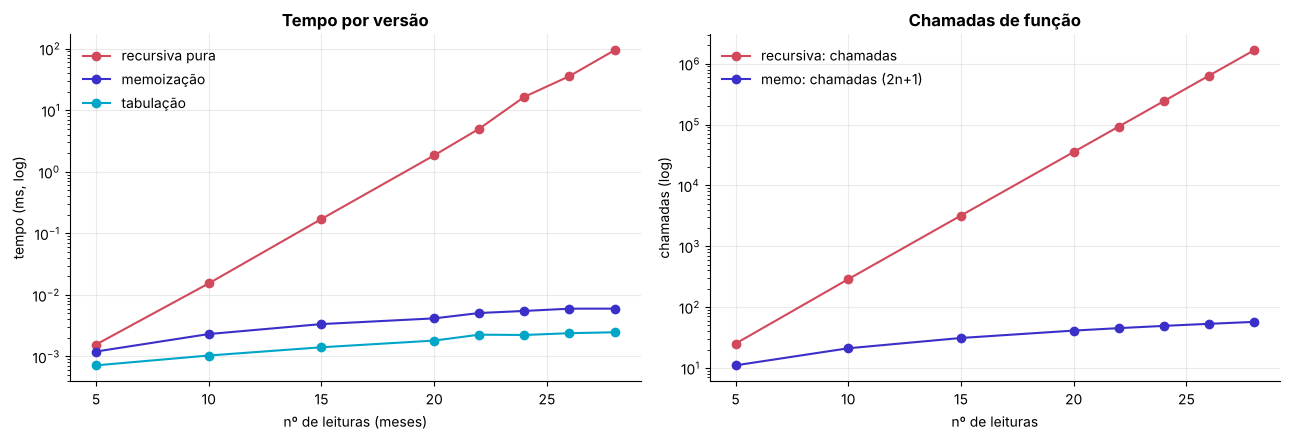

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(bench.index, bench["recursiva_ms"], "o-", color=COR["rec"], label="recursiva pura")
axs[0].plot(bench.index, bench["memo_ms"], "o-", color=COR["memo"], label="memoização")
axs[0].plot(bench.index, bench["tabulacao_ms"], "o-", color=COR["tab"], label="tabulação")
axs[0].set_yscale("log"); axs[0].set(xlabel="nº de leituras (meses)", ylabel="tempo (ms, log)", title="Tempo por versão"); axs[0].legend(frameon=False)
axs[1].plot(bench.index, bench["chamadas_recursiva"], "o-", color=COR["rec"], label="recursiva: chamadas")
axs[1].plot(bench.index, [2 * n + 1 for n in bench.index], "o-", color=COR["memo"], label="memo: chamadas (2n+1)")
axs[1].set_yscale("log"); axs[1].set(xlabel="nº de leituras", ylabel="chamadas (log)", title="Chamadas de função"); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretação — degradação acumulada (três versões):**
- **Corretude:** as três versões dão **exatamente o mesmo valor** (diferença 0,0 nas 201 escadas), e o ranking por memoização é idêntico ao da tabulação.
- **Recursiva pura:** o nº de chamadas segue exatamente **2·F(n+2) − 1** (Fibonacci), confirmado na tabela. Cada mês a mais multiplica o trabalho por ≈ φ = 1,618.
  Com 28 meses já são 1,7 milhão de chamadas (~0,1 s). Para os 45 meses reais seriam ~5,9 bilhões de chamadas: **≈ 5 min por escada e ≈ 17 h para as 201** (o valor exato varia com a máquina). É inviável.
- **Memoização:** cada D(t) é calculado uma vez (2n+1 chamadas), em microssegundos. O limite é a **pilha de recursão** do Python: a partir de ~1.000 leituras
  dá `RecursionError`. Com leituras diárias ou horárias de sensores, esse limite chega rápido.
- **Tabulação:** mesma complexidade O(n), sem recursão. Calcula as 201 escadas completas em **poucos milissegundos** e 100 mil leituras em ~10 ms.
  **É a versão usada no ranking e no `planejar_turno`.** Poderia ainda usar memória O(1), guardando só D(t−1) e D(t−2), mas mantemos a tabela para plotar D(t).

## 2. Ranking das escadas por criticidade
A criticidade de cada escada é a **degradação acumulada na última leitura** (set/2026), calculada com a tabulação.
Como a recorrência é linear, a degradação final pode ser separada pela contribuição de cada família. Isso mostra **por que** cada escada está no topo.

In [8]:
ranking = dg.ranking_criticidade(leituras, PESOS, ALFA, BETA, versao="tabulacao")
rk = pd.DataFrame([{**{k: r[k] for k in ["posicao", "escada", "degradacao", "familia_dominante"]},
                    "estacao": cadastro[r["escada"]]["nome_estacao"],
                    **{f"contrib_{f}": round(v, 2) for f, v in r["contribuicao"].items()}} for r in ranking])
print(f"Escadas com degradação > 0: {(rk['degradacao'] > 0).sum()} de {len(rk)}")
rk.head(15).round(2)

Escadas com degradação > 0: 197 de 201


,posicao,escada,degradacao,familia_dominante,estacao,contrib_vibracao,contrib_temperatura,contrib_corrente_tensao,contrib_oleo,contrib_velocidade
0,1,REP-ER59,7.37,vibracao,República,6.59,0.00,0.74,0.01,0.04
1,2,LUZ-ER11,7.05,vibracao,Luz,6.64,0.00,0.20,0.01,0.19
2,3,PIN-ER24,6.16,vibracao,Pinheiros,3.55,0.02,0.43,0.39,1.78
3,4,PTA-ER09,5.41,vibracao,Paulista,4.96,0.01,0.09,0.01,0.36
4,5,PIN-ER21,4.97,temperatura,Pinheiros,2.36,2.51,0.00,0.00,0.10
5,6,LUZ-ER13,4.66,vibracao,Luz,4.28,0.00,0.37,0.00,0.00
6,7,PIN-ER06,4.56,vibracao,Pinheiros,4.37,0.00,0.01,0.10,0.07
7,8,BUT-ER05,4.09,corrente_tensao,Butantã,0.66,0.00,3.42,0.00,0.00
8,9,BUT-ER12,3.79,vibracao,Butantã,2.59,0.00,1.12,0.00,0.08
9,10,BUT-ER13,3.62,corrente_tensao,Butantã,0.66,0.00,2.71,0.24,0.00


Ranking por memoização idêntico ao da tabulação: True


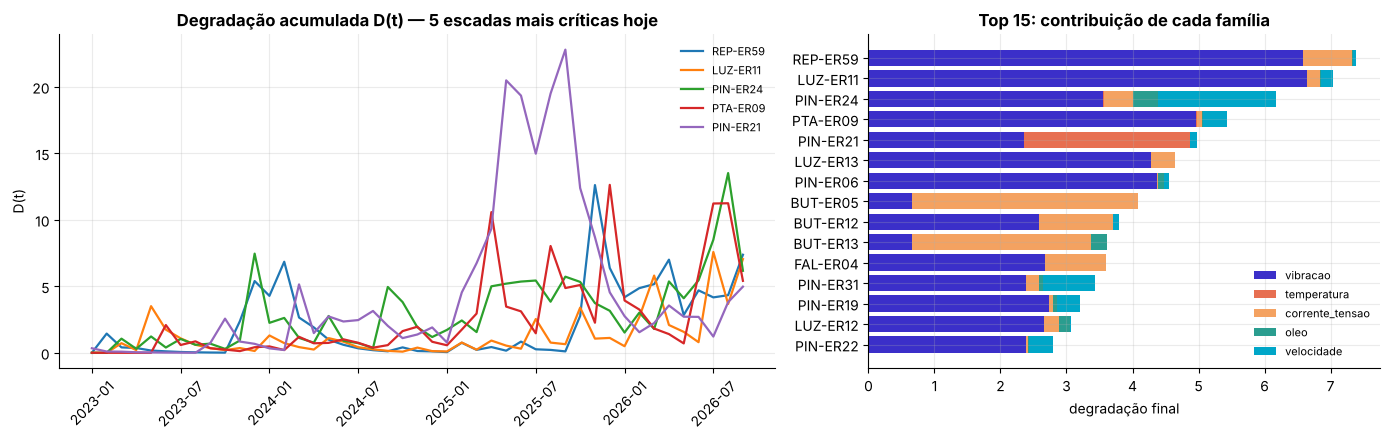

In [9]:
# o ranking é o mesmo nas três versões? (memo em todas as escadas; recursiva pura inviável com 45 meses)
rk_memo = dg.ranking_criticidade(leituras, PESOS, ALFA, BETA, versao="memo")
print("Ranking por memoização idêntico ao da tabulação:", [r["escada"] for r in rk_memo] == [r["escada"] for r in ranking])

top = rk.head(5)["escada"]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
meses = [l["mes"] for l in leituras[top.iloc[0]]]
for esc in top:
    d = dg.degradacao_tabulacao(dg.serie_severidade(leituras[esc], PESOS), ALFA, BETA)
    axs[0].plot(range(len(d)), d, lw=1.6, label=esc)
axs[0].set_xticks(range(0, len(meses), 6), meses[::6], rotation=45); axs[0].legend(frameon=False, fontsize=8)
axs[0].set(title="Degradação acumulada D(t) — 5 escadas mais críticas hoje", ylabel="D(t)")
t15 = rk.head(15).set_index("escada")[[f"contrib_{f}" for f in dg.FAMILIAS]].iloc[::-1]
left = np.zeros(len(t15))
cores_f = {"vibracao": "#3b2fc9", "temperatura": "#e76f51", "corrente_tensao": "#f4a261", "oleo": "#2a9d8f", "velocidade": "#00a6c8"}
for f in dg.FAMILIAS:
    axs[1].barh(t15.index, t15[f"contrib_{f}"], left=left, color=cores_f[f], label=f); left += t15[f"contrib_{f}"].values
axs[1].legend(frameon=False, fontsize=8); axs[1].set(title="Top 15: contribuição de cada família", xlabel="degradação final")
plt.tight_layout(); plt.show()

In [10]:
por_est = rk.groupby("estacao").agg(escadas=("escada", "size"), degradacao_media=("degradacao", "mean"),
                                    no_top30=("posicao", lambda p: (p <= 30).sum())).sort_values("degradacao_media", ascending=False)
por_est.round(2)

,escadas,degradacao_media,no_top30
estacao,,,
Butantã,14,1.59,6
Luz,20,1.40,7
República,7,1.29,1
Pinheiros,32,1.20,7
Faria Lima,10,0.91,2
Paulista,18,0.70,3
São Paulo-Morumbi,15,0.57,1
Terminal Vila Sônia,9,0.37,0
Vila Sônia,20,0.36,2


**Interpretação — ranking por criticidade:**
- O topo do ranking (REP-ER59, LUZ-ER11, PIN-ER24, PTA-ER09, PIN-ER21) é dominado por **vibração**. Essa família tem o maior peso porque, nos dados reais,
  suas falhas (redutor, eixo, corrente principal) deixam a escada parada por mais tempo. Duas escadas de Butantã aparecem por **corrente/tensão** e a PIN-ER21 por **temperatura**,
  coerente com a EDA (Butantã concentra falhas elétricas e Pinheiros é a única estação com peso relevante de temperatura).
- A decomposição por família (gráfico da direita) torna o ranking **explicável**: a equipe sabe em qual subsistema começar a inspeção de cada escada.
- O gráfico de D(t) mostra a **memória curta** do modelo (α + β ≈ 0,45): a PIN-ER21 chegou a D ≈ 23 em meados de 2025 e "esfriou" depois do reparo.
  Escadas entram e saem do topo conforme a condição **recente**, que é a lógica da manutenção baseada em condição, diferente do calendário fixo.
- Por estação, **Butantã, Luz, República e Pinheiros** têm a maior degradação média, e Higienópolis e Oscar Freire a menor, o mesmo padrão de falhas por escada-ano encontrado na EDA.
- Limitação: a última leitura (set/2026) é parcial (dados até 22/09). O ranking também usa só as falhas que os 5 sinais poderiam detectar.
  Desarmes de corrimão, freio e pente ficam fora, por definição do desafio.

## 3. Rede de estações como grafo
### 3.1 Modelagem
- **Vértices (13):** as 11 estações da Linha 4-Amarela (operada pela ViaQuatro, concessionária da Motiva), o Terminal Vila Sônia
  (os 12 locais com escadas rolantes no plano PMP-6ECR-0001) e **1 base de manutenção** junto ao pátio de Vila Sônia.
- **Arestas (34):** trechos com peso em **minutos** de deslocamento, em três modos: `metro` (entre estações vizinhas), `a_pe` (Vila Sônia ↔ Terminal)
  e `viatura` (por rua: entre vizinhas, da base às estações e alguns atalhos). O cálculo de cada peso está em `scripts/gerar_rede.py`.
- **Representação:** lista de adjacência `{vértice: [(vizinho, minutos, modo), ...]}`.
- **Escadas → estações:** cada escada do dataset tem o código da estação no próprio identificador (ex.: `PIN-ER24` → Pinheiros).

In [11]:
adj = grafo.montar_adjacencia(rede)
coords = grafo.coordenadas(rede)
nomes = {v["id"]: v["nome"] for v in rede["vertices"]}
print("Lista de adjacência:")
for v, viz in adj.items():
    print(f"  {v:4s} → " + ", ".join(f"{u}({w:g} min, {m})" for u, w, m in viz))
sem_estacao = [e for e, c in cadastro.items() if c["estacao"] not in adj]
print(f"\nEscadas ligadas a uma estação do grafo: {len(cadastro) - len(sem_estacao)} de {len(cadastro)}")
pd.Series({c["estacao"]: 0 for c in cadastro.values()}).index.to_series().map(
    lambda s: sum(1 for c in cadastro.values() if c["estacao"] == s)).rename("escadas no dataset").to_frame().T

Lista de adjacência:
  LUZ  → HIG(14.9 min, viatura), PTA(21.2 min, viatura), REP(3.2 min, metro), REP(10.5 min, viatura)
  REP  → HIG(2.9 min, metro), HIG(9.7 min, viatura), LUZ(3.2 min, metro), LUZ(10.5 min, viatura)
  HIG  → LUZ(14.9 min, viatura), PTA(3.6 min, metro), PTA(11.3 min, viatura), REP(2.9 min, metro), REP(9.7 min, viatura)
  PTA  → BASE(49.6 min, viatura), FAL(21 min, viatura), FRE(3.4 min, metro), FRE(10.9 min, viatura), HIG(3.6 min, metro), HIG(11.3 min, viatura), LUZ(21.2 min, viatura)
  FRE  → BUT(23.1 min, viatura), FRA(3.6 min, metro), FRA(11.3 min, viatura), PTA(3.4 min, metro), PTA(10.9 min, viatura)
  FRA  → FAL(2.7 min, metro), FAL(9.1 min, viatura), FRE(3.6 min, metro), FRE(11.3 min, viatura), PIN(13.3 min, viatura)
  FAL  → FRA(2.7 min, metro), FRA(9.1 min, viatura), PIN(2.8 min, metro), PIN(9.3 min, viatura), PTA(21 min, viatura)
  PIN  → BASE(30.5 min, viatura), BUT(2.6 min, metro), BUT(9 min, viatura), FAL(2.8 min, metro), FAL(9.3 min, viatura), FRA(13.3 m

,BUT,FAL,FRA,FRE,HIG,LUZ,MBI,PIN,PTA,REP,TVS,VSO
escadas no dataset,14,10,10,20,26,20,15,32,18,7,9,20


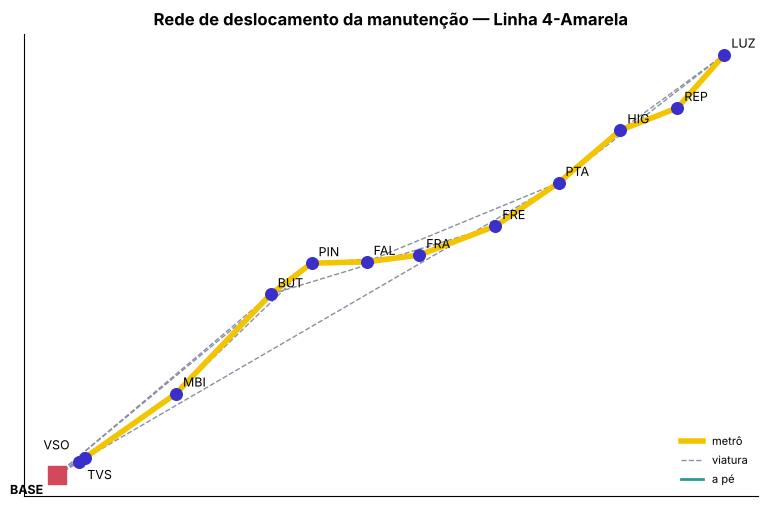

In [12]:
def desenhar_rede(ax, destaque=None, titulo=""):
    estilo = {"metro": dict(color="#f2c500", lw=4, zorder=1), "viatura": dict(color=COR["neutra"], lw=1, ls="--", zorder=0),
              "a_pe": dict(color="#2a9d8f", lw=2, zorder=1)}
    for a in rede["arestas"]:
        (y1, x1), (y2, x2) = coords[a["origem"]], coords[a["destino"]]
        ax.plot([x1, x2], [y1, y2], **estilo[a["modo"]])
    if destaque:
        for (u, _), (v, m) in zip(destaque, destaque[1:]):
            (y1, x1), (y2, x2) = coords[u], coords[v]
            ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#d1495b", lw=2.2), zorder=3)
    for v, (y, x) in coords.items():
        base = v == "BASE"
        ax.scatter(x, y, s=150 if base else 70, color="#d1495b" if base else "#3b2fc9", marker="s" if base else "o", zorder=4)
        off = {"BASE": (-34, -14), "TVS": (6, -12), "VSO": (-30, 6)}.get(v, (5, 5))
        ax.annotate(v, (x, y), xytext=off, textcoords="offset points", fontsize=9, weight="bold" if base else None)
    ax.set_aspect(1 / math.cos(math.radians(-23.57))); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(titulo)
    ax.plot([], [], color="#f2c500", lw=4, label="metrô"); ax.plot([], [], color=COR["neutra"], lw=1, ls="--", label="viatura")
    ax.plot([], [], color="#2a9d8f", lw=2, label="a pé"); ax.legend(frameon=False, fontsize=8, loc="lower right")

fig, ax = plt.subplots(figsize=(11, 6))
desenhar_rede(ax, titulo="Rede de deslocamento da manutenção — Linha 4-Amarela")
plt.show()

### 3.2 BFS (menos trechos) × Dijkstra (menor tempo), partindo da base

In [13]:
saltos, pred_bfs = grafo.bfs(adj, "BASE")
dist, pred_dij, _ = grafo.dijkstra(adj, "BASE")
def tempo_rota(rota):
    t = 0.0
    for (u, _), (v, m) in zip(rota, rota[1:]):
        t += min(w for x, w, mm in adj[u] if x == v and mm == m)
    return t
comp = []
for est in [v for v in adj if v != "BASE"]:
    rb, rd = grafo.reconstruir_rota(pred_bfs, "BASE", est), grafo.reconstruir_rota(pred_dij, "BASE", est)
    comp.append({"destino": f"{est} — {nomes[est]}", "BFS_trechos": saltos[est], "BFS_minutos": round(tempo_rota(rb), 1),
                 "Dijkstra_trechos": len(rd) - 1, "Dijkstra_minutos": round(dist[est], 1),
                 "rota_BFS": grafo.formatar_rota(rb), "rota_Dijkstra": grafo.formatar_rota(rd)})
comp = pd.DataFrame(comp)
comp["minutos_economizados"] = comp["BFS_minutos"] - comp["Dijkstra_minutos"]
comp[["destino", "BFS_trechos", "BFS_minutos", "Dijkstra_trechos", "Dijkstra_minutos", "minutos_economizados"]]

,destino,BFS_trechos,BFS_minutos,Dijkstra_trechos,Dijkstra_minutos,minutos_economizados
0,LUZ — Luz,2,70.8,11,42.2,28.6
1,REP — República,3,56.1,10,39.0,17.1
2,HIG — Higienópolis-Mackenzie,2,53.2,9,36.1,17.1
3,PTA — Paulista,1,49.6,8,32.5,17.1
4,FRE — Oscar Freire,2,49.6,7,29.1,20.5
5,FRA — Fradique Coutinho,2,43.8,6,25.5,18.3
6,FAL — Faria Lima,2,33.3,5,22.8,10.5
7,PIN — Pinheiros,1,30.5,4,20.0,10.5
8,BUT — Butantã,1,26.5,3,17.4,9.1
9,MBI — São Paulo-Morumbi,1,16.1,2,12.1,4.0


In [14]:
for _, r in comp.iterrows():
    if r["rota_BFS"] != r["rota_Dijkstra"]:
        print(f"{r['destino']}\n   BFS      ({r['BFS_minutos']:5.1f} min): {r['rota_BFS']}\n   Dijkstra ({r['Dijkstra_minutos']:5.1f} min): {r['rota_Dijkstra']}")

LUZ — Luz
   BFS      ( 70.8 min): BASE →(viatura) PTA →(viatura) LUZ
   Dijkstra ( 42.2 min): BASE →(viatura) VSO →(metro) MBI →(metro) BUT →(metro) PIN →(metro) FAL →(metro) FRA →(metro) FRE →(metro) PTA →(metro) HIG →(metro) REP →(metro) LUZ
REP — República
   BFS      ( 56.1 min): BASE →(viatura) PTA →(metro) HIG →(metro) REP
   Dijkstra ( 39.0 min): BASE →(viatura) VSO →(metro) MBI →(metro) BUT →(metro) PIN →(metro) FAL →(metro) FRA →(metro) FRE →(metro) PTA →(metro) HIG →(metro) REP
HIG — Higienópolis-Mackenzie
   BFS      ( 53.2 min): BASE →(viatura) PTA →(metro) HIG
   Dijkstra ( 36.1 min): BASE →(viatura) VSO →(metro) MBI →(metro) BUT →(metro) PIN →(metro) FAL →(metro) FRA →(metro) FRE →(metro) PTA →(metro) HIG
PTA — Paulista
   BFS      ( 49.6 min): BASE →(viatura) PTA
   Dijkstra ( 32.5 min): BASE →(viatura) VSO →(metro) MBI →(metro) BUT →(metro) PIN →(metro) FAL →(metro) FRA →(metro) FRE →(metro) PTA
FRE — Oscar Freire
   BFS      ( 49.6 min): BASE →(viatura) BUT →(viatura)

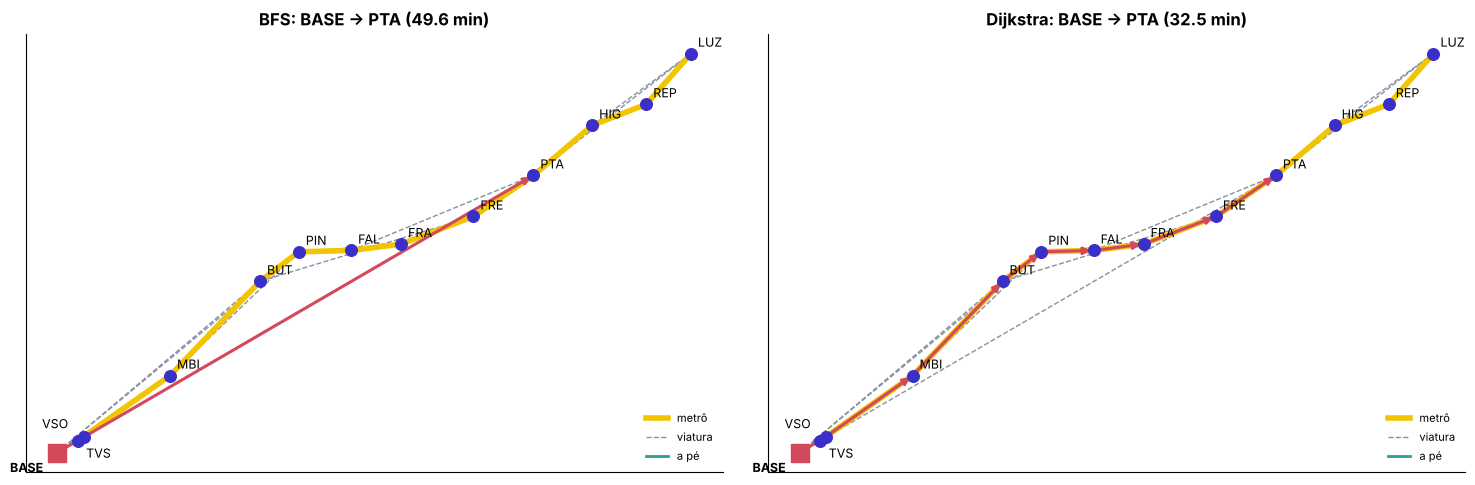

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
desenhar_rede(axs[0], grafo.reconstruir_rota(pred_bfs, "BASE", "PTA"), f"BFS: BASE → PTA ({comp.set_index('destino').filter(like='PTA', axis=0)['BFS_minutos'].iloc[0]} min)")
desenhar_rede(axs[1], grafo.reconstruir_rota(pred_dij, "BASE", "PTA"), f"Dijkstra: BASE → PTA ({dist['PTA']:.1f} min)")
plt.tight_layout(); plt.show()

**Interpretação — BFS × Dijkstra:**
- O **BFS** minimiza o **nº de trechos**, por isso prefere os atalhos de viatura (BASE → PTA direto, 1 trecho). Esses atalhos são **mais lentos**: 49,6 min até Paulista.
- O **Dijkstra** minimiza o **tempo**: viatura até Vila Sônia e depois metrô (8 trechos, **32,5 min**). Para Luz, a economia é de **28,6 min (−40%)**.
  Só para Vila Sônia e o Terminal, vizinhos da base, os dois coincidem.
- Para o técnico, o que importa é o tempo de chegada à escada, então o **Dijkstra é o algoritmo usado no planejamento**.
  O BFS seria o critério certo se cada trecho tivesse um custo fixo dominante (ex.: cada baldeação exigir carregar ferramentas pesadas).
- A rota é **reconstruída** a partir do dicionário de predecessores (`reconstruir_rota`), que guarda também o **modo** de cada trecho.

## 4. Otimização de rotas com A*
### 4.1 Heurística e justificativa
$$h(n) = \frac{D(n)}{v_{máx}}\cdot 60 \;+\; \left\lceil \frac{D(n)}{L_{máx}} \right\rceil \cdot c_{mín}$$

- $D(n)$: distância em linha reta (haversine) de $n$ até o destino;
- $v_{máx}$: maior velocidade **efetiva** entre os modos disponíveis (metrô = 32 km/h de dia; à noite, sem metrô, a viatura = 18 km/h ÷ 1,4 de sinuosidade ≈ 12,9 km/h);
- $c_{mín}$: menor custo fixo de um trecho (1 min de parada do metrô / caminhada; 5 min para estacionar a viatura);
- $L_{máx}$: maior comprimento em linha reta de um trecho da rede.

**Admissível** (nunca superestima): todo trecho custa pelo menos $\text{dist}/v_{máx} + c_{mín}$. Para cobrir a distância $D(n)$ são necessários
no mínimo $\lceil D(n)/L_{máx}\rceil$ trechos, então o custo real restante é ≥ $h(n)$. Isso garante que o A* devolve **o mesmo ótimo do Dijkstra**.

**Consistente:** pela desigualdade triangular, $D(u) \le D(v) + \text{dist}(u,v)$ e $\lceil D(u)/L\rceil \le \lceil D(v)/L\rceil + 1$, logo $h(u) \le w(u,v) + h(v)$.
O A* nunca precisa reabrir um vértice.

Também testamos a versão mais simples (só a primeira parcela, "linha reta na velocidade máxima") para medir o ganho da segunda parcela.
As duas propriedades são verificadas numericamente em todas as arestas e destinos, de dia e de noite:

In [16]:
adj_noite = grafo.montar_adjacencia(rede, modos={"viatura", "a_pe"})
REDES = {"diurna": (adj, grafo.parametros_heuristica(rede)), "noturna": (adj_noite, grafo.parametros_heuristica(rede, {"viatura", "a_pe"}))}
for nome_r, (a_, (v, c, L)) in REDES.items():
    viol_adm = viol_cons = 0
    for destino in a_:
        h = grafo.heuristica_tempo(coords, destino, v, c, L)
        d_real, _, _ = grafo.dijkstra(a_, destino)
        viol_adm += sum(h(u) > d_real[u] + 1e-9 for u in a_)
        viol_cons += sum(h(u) > w + h(v_) + 1e-9 for u in a_ for v_, w, _ in a_[u])
    print(f"Rede {nome_r}: v_máx = {v:.2f} km/h, c_mín = {c} min, L_máx = {L:.2f} km → "
          f"violações de admissibilidade: {viol_adm} | de consistência: {viol_cons}")

Rede diurna: v_máx = 32.00 km/h, c_mín = 1.0 min, L_máx = 9.55 km → violações de admissibilidade: 0 | de consistência: 0
Rede noturna: v_máx = 12.86 km/h, c_mín = 1.0 min, L_máx = 9.55 km → violações de admissibilidade: 0 | de consistência: 0


### 4.2 A* × Dijkstra na rede da Linha 4

In [17]:
linhas = []
for nome_r, (a_, (v, c, L)) in REDES.items():
    for origem in ["BASE", "LUZ"]:
        for destino in [x for x in a_ if x != origem]:
            h = grafo.heuristica_tempo(coords, destino, v, c, L)
            c_a, p_a, e_a = grafo.a_estrela(a_, origem, destino, h)
            d_d, p_d, e_d = grafo.dijkstra(a_, origem, destino)
            linhas.append({"rede": nome_r, "origem": origem, "destino": destino, "custo_A*": round(c_a, 1), "custo_Dijkstra": round(d_d[destino], 1),
                           "expandidos_A*": e_a, "expandidos_Dijkstra": e_d,
                           "us_A*": dg.medir(lambda: grafo.a_estrela(a_, origem, destino, grafo.heuristica_tempo(coords, destino, v, c, L)), 300) * 1e6,
                           "us_Dijkstra": dg.medir(lambda: grafo.dijkstra(a_, origem, destino), 300) * 1e6,
                           "mesma_rota": grafo.reconstruir_rota(p_a, origem, destino) == grafo.reconstruir_rota(p_d, origem, destino)})
astar = pd.DataFrame(linhas)
print("Custos idênticos em todos os pares:", (astar["custo_A*"] == astar["custo_Dijkstra"]).all(), "| mesmas rotas:", astar["mesma_rota"].all())
resumo_astar = astar.groupby(["rede", "origem"])[["expandidos_A*", "expandidos_Dijkstra", "us_A*", "us_Dijkstra"]].mean().round(1)
resumo_astar["redução_expansões_%"] = (1 - resumo_astar["expandidos_A*"] / resumo_astar["expandidos_Dijkstra"]) * 100
resumo_astar.round(1)

Custos idênticos em todos os pares: True | mesmas rotas: True


expandidos_A*  expandidos_Dijkstra  us_A*  us_Dijkstra  redução_expansões_%
rede    origem                                                                             
diurna  BASE              7.4                  7.5   15.3          6.4                  1.3
        LUZ               7.5                  7.5   17.3          6.7                  0.0
noturna BASE              5.1                  7.5   14.6          5.3                 32.0
        LUZ               6.1                  7.5   11.9          5.3                 18.7

In [18]:
astar[(astar["rede"] == "noturna") & (astar["origem"] == "LUZ")].drop(columns=["rede", "origem"]).round(1)

,destino,custo_A*,custo_Dijkstra,expandidos_A*,expandidos_Dijkstra,us_A*,us_Dijkstra,mesma_rota
36,REP,10.5,10.5,2,2,5.0,1.2,True
37,HIG,14.9,14.9,2,3,4.8,1.2,True
38,PTA,21.2,21.2,2,4,5.7,2.7,True
39,FRE,32.1,32.1,5,5,10.5,3.2,True
40,FRA,43.4,43.4,6,7,11.6,4.2,True
41,FAL,42.2,42.2,5,6,9.9,3.3,True
42,PIN,51.5,51.5,7,8,14.6,4.5,True
43,BUT,55.2,55.2,7,9,14.4,5.3,True
44,MBI,70.8,70.8,10,11,16.3,7.3,True
45,VSO,78.4,78.4,11,13,20.3,7.7,True


### 4.3 Escalabilidade: rede ampliada
A rede da Linha 4 é pequena (13 vértices) e quase linear, então a diferença é de microssegundos. Para ver como os algoritmos escalam
(ex.: incluir as linhas 5, 8 e 9 e outras concessões da Motiva), geramos **malhas sintéticas** com coordenadas na mesma região
e os mesmos tipos de trecho, de dia (metrô + viatura) e de noite (só viatura). Comparamos Dijkstra, A* só com a parcela da distância
e A* com a heurística completa, em 20 pares origem-destino aleatórios por tamanho.

In [19]:
def malha(lado, noturno=False, seed=7):
    """Malha lado×lado sobre a região de SP; trechos entre vizinhos (metrô a cada 4 linhas de dia, viatura no resto)."""
    rnd = random.Random(seed)
    pos = {f"N{i}_{j}": (-23.50 - i * .01 + rnd.uniform(-.002, .002), -46.75 + j * .01 + rnd.uniform(-.002, .002))
           for i in range(lado) for j in range(lado)}
    adj_m, l_max = {k: [] for k in pos}, 0.0
    for i in range(lado):
        for j in range(lado):
            u = f"N{i}_{j}"
            for di, dj in [(0, 1), (1, 0)]:
                if i + di < lado and j + dj < lado:
                    v_ = f"N{i+di}_{j+dj}"; km = grafo.haversine_km(pos[u], pos[v_]); l_max = max(l_max, km)
                    modo = "metro" if (i % 4 == 0 and di == 0 and not noturno) else "viatura"
                    w = km / 32 * 60 + 1 if modo == "metro" else km * 1.4 / 18 * 60 + 5
                    adj_m[u].append((v_, w, modo)); adj_m[v_].append((u, w, modo))
    params = (12.8571, 5.0, l_max) if noturno else (32.0, 1.0, l_max)
    return adj_m, pos, params

esc = []
for noturno in [False, True]:
    for lado in [10, 20, 40, 60]:
        adj_m, pos_m, (v, c, L) = malha(lado, noturno)
        rnd = random.Random(lado)
        pares = [(f"N{rnd.randrange(lado)}_{rnd.randrange(lado)}", f"N{rnd.randrange(lado)}_{rnd.randrange(lado)}") for _ in range(20)]
        acc = {"exp_D": 0, "exp_A1": 0, "exp_A2": 0, "t_D": 0, "t_A1": 0, "t_A2": 0}
        for o, d in pares:
            dd, _, ed = grafo.dijkstra(adj_m, o, d)
            c1, _, e1 = grafo.a_estrela(adj_m, o, d, grafo.heuristica_tempo(pos_m, d, v))
            c2, _, e2 = grafo.a_estrela(adj_m, o, d, grafo.heuristica_tempo(pos_m, d, v, c, L))
            assert abs(c1 - dd[d]) < 1e-9 and abs(c2 - dd[d]) < 1e-9
            acc["exp_D"] += ed; acc["exp_A1"] += e1; acc["exp_A2"] += e2
            acc["t_D"] += dg.medir(lambda: grafo.dijkstra(adj_m, o, d), 3)
            acc["t_A1"] += dg.medir(lambda: grafo.a_estrela(adj_m, o, d, grafo.heuristica_tempo(pos_m, d, v)), 3)
            acc["t_A2"] += dg.medir(lambda: grafo.a_estrela(adj_m, o, d, grafo.heuristica_tempo(pos_m, d, v, c, L)), 3)
        esc.append({"rede": "noturna" if noturno else "diurna", "vértices": lado * lado,
                    "expandidos_Dijkstra": acc["exp_D"] / 20, "expandidos_A*_simples": acc["exp_A1"] / 20, "expandidos_A*_completa": acc["exp_A2"] / 20,
                    "ms_Dijkstra": acc["t_D"] / 20 * 1e3, "ms_A*_simples": acc["t_A1"] / 20 * 1e3, "ms_A*_completa": acc["t_A2"] / 20 * 1e3})
esc = pd.DataFrame(esc).set_index(["rede", "vértices"])
esc["redução_expansões_completa_%"] = (1 - esc["expandidos_A*_completa"] / esc["expandidos_Dijkstra"]) * 100
esc["ganho_tempo_completa_%"] = (1 - esc["ms_A*_completa"] / esc["ms_Dijkstra"]) * 100
esc.round(2)

expandidos_Dijkstra  expandidos_A*_simples  expandidos_A*_completa  ms_Dijkstra  ms_A*_simples  ms_A*_completa  redução_expansões_completa_%  ganho_tempo_completa_%
rede    vértices                                                                                                                                                                      
diurna  100                     46.70                  37.45                   33.50         0.03           0.06            0.06                         28.27                  -91.82
        400                    206.50                 155.35                  136.65         0.14           0.25            0.23                         33.83                  -61.25
        1600                   814.70                 638.40                  582.95         0.67           1.17            1.07                         28.45                  -60.29
        3600                  2317.30                1977.00                 1854.95         2.91           4.56            4.32                         19.95                  -48.56
noturna 100                     46.90                  28.15                   15.80         0.04           0.06            0.04                         66.31                    0.56
        400                    220.75                 141.05                   81.45         0.19           0.29            0.18                         63.10                    4.46
        1600                   854.40                 562.05                  337.30         0.93           1.40            0.91                         60.52                    2.96
        3600                  2114.95                1424.10                  888.85         2.59           3.72            2.41                         57.97                    6.86

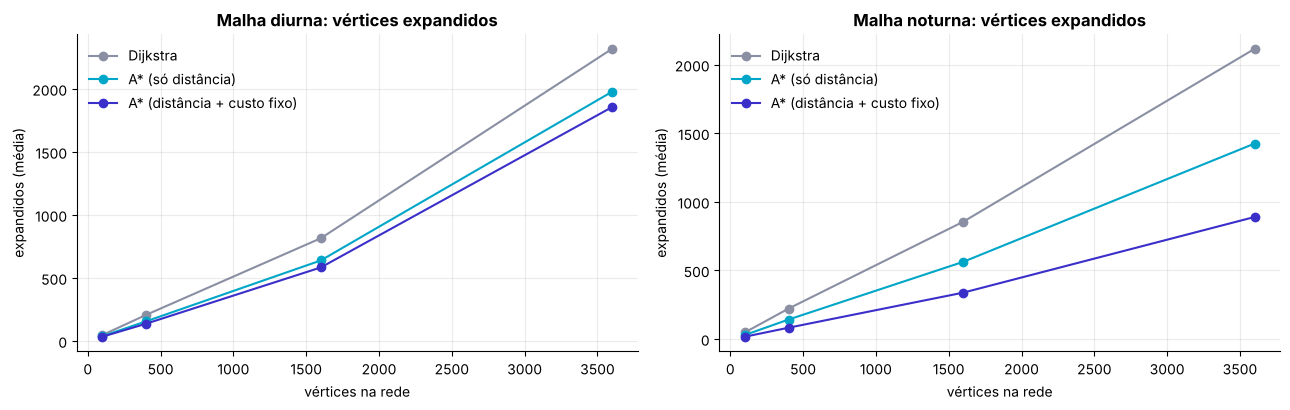

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, rede_n in zip(axs, ["diurna", "noturna"]):
    e = esc.loc[rede_n]
    ax.plot(e.index, e["expandidos_Dijkstra"], "o-", color=COR["neutra"], label="Dijkstra")
    ax.plot(e.index, e["expandidos_A*_simples"], "o-", color=COR["tab"], label="A* (só distância)")
    ax.plot(e.index, e["expandidos_A*_completa"], "o-", color=COR["memo"], label="A* (distância + custo fixo)")
    ax.set(title=f"Malha {rede_n}: vértices expandidos", xlabel="vértices na rede", ylabel="expandidos (média)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretação — A\*:**
- O A\* encontrou **sempre o mesmo custo e a mesma rota** do Dijkstra (todos os pares, dia e noite), como garantido pela heurística admissível e consistente.
- **Na Linha 4 de dia**, o A\* expande praticamente os mesmos vértices: a rede é uma **linha** e a heurística é "frouxa", porque supõe o metrô (32 km/h)
  em trechos que, na prática, começam de viatura. Com o custo extra de calcular a heurística, ele fica ~2× mais lento em microssegundos.
- **À noite** (sem metrô), a velocidade máxima cai para a da viatura, a heurística fica mais **justa** e o A\* expande **19–32% menos** vértices na rede real.
- **Nas malhas maiores**, a parcela do custo fixo (⌈D/L⌉·c) faz diferença: à noite o A\* expande **58–66% menos** vértices e fica ~10% **mais rápido** a partir de 1.600 vértices.
  De dia, expande 20–34% menos, mas não compensa o custo da heurística em Python.
- **Conclusão:** para a Linha 4 sozinha, Dijkstra basta. Se a rede crescer (todas as linhas e concessões da Motiva) e para o **planejamento noturno por viatura**,
  o A\* com a heurística completa é a escolha: dá o mesmo resultado com bem menos trabalho.

## 5. Plano de manutenção do turno — `planejar_turno(base, horas)`
Regra implementada em `src/planejamento.py`:
1. candidatas = as 30 escadas mais críticas do ranking (degradação > 0);
2. a partir da posição atual, vai para a **escada mais crítica ainda não atendida** cujo *deslocamento (Dijkstra) + atendimento + volta à base* cabe no tempo restante;
3. na estação, atende também as outras candidatas **da mesma estação** (sem novo deslocamento), em ordem de criticidade;
4. repete até nada mais caber e volta à base pela rota de menor tempo.

O **tempo de atendimento** de cada escada é a mediana real (horas de mão de obra ÷ nº de técnicos) das falhas com reparo dessa escada (EDA, seção 7.3).

In [21]:
plano = planejar_turno("BASE", 6)
print("Turno diurno de 6 h (metrô + viatura):", plano["resumo"])
pd.DataFrame(plano["visitas"])[["ordem", "escada", "estacao", "posicao_ranking", "degradacao", "familia_dominante",
                                "chegada", "atendimento_min", "fim", "deslocamento_min", "rota"]]

Turno diurno de 6 h (metrô + viatura): {'base': 'BASE', 'horas_turno': 6, 'inicio': '08:00', 'termino': '13:44', 'escadas_atendidas': 5, 'candidatas': 30, 'tempo_usado_min': 344.8, 'deslocamento_min': 84.4, 'atendimento_min': 260.4, 'ocioso_min': 15.2, 'pct_degradacao_coberta': 25.7}


,ordem,escada,estacao,posicao_ranking,degradacao,familia_dominante,chegada,atendimento_min,fim,deslocamento_min,rota
0,1,REP-ER59,REP,1,7.37,vibracao,08:39,56.4,09:35,39.0,BASE →(viatura) VSO →(metro) MBI →(metro) BUT →(metro) PIN →(metro) FAL →(metro) FRA →(metro) FRE →(metro) PTA →(metro) HIG →(metro) REP
1,2,LUZ-ER11,LUZ,2,7.05,vibracao,09:38,43.8,10:22,3.2,REP →(metro) LUZ
2,3,LUZ-ER13,LUZ,6,4.66,vibracao,10:22,49.8,11:12,0.0,LUZ (mesma estação)
3,4,LUZ-ER12,LUZ,14,3.07,vibracao,11:12,60.0,12:12,0.0,LUZ (mesma estação)
4,5,LUZ-ER09,LUZ,18,2.56,temperatura,12:12,50.4,13:02,0.0,LUZ (mesma estação)


Retorno à base: {'rota': 'LUZ →(metro) REP →(metro) HIG →(metro) PTA →(metro) FRE →(metro) FRA →(metro) FAL →(metro) PIN →(metro) BUT →(metro) MBI →(metro) VSO →(viatura) BASE', 'deslocamento_min': 42.2, 'chegada': '13:44'}


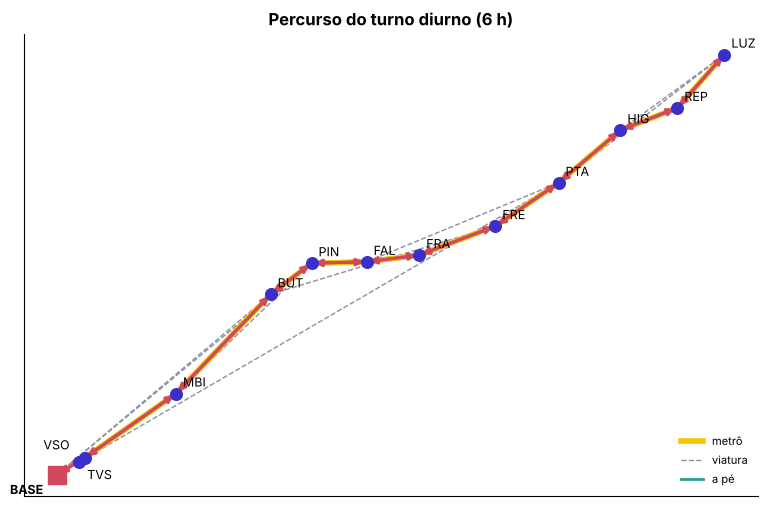

In [22]:
print("Retorno à base:", plano["retorno"])
fig, ax = plt.subplots(figsize=(11, 6))
rota_turno = [("BASE", None)]
for v in plano["visitas"]:
    if v["deslocamento_min"] > 0:
        partes = v["rota"].split(" →(")
        for p in partes[1:]:
            modo, no = p.split(") ")
            rota_turno.append((no, modo))
for p in plano["retorno"]["rota"].split(" →(")[1:]:
    modo, no = p.split(") ")
    rota_turno.append((no, modo))
desenhar_rede(ax, rota_turno, "Percurso do turno diurno (6 h)")
plt.show()

### 5.1 Coerência do plano com os dados
Conferências automáticas: o turno cabe nas horas, a ordem respeita a criticidade (exceto escadas atendidas "de passagem" na mesma estação)
e nenhuma escada mais crítica que caberia no turno ficou de fora.

In [23]:
def conferir(plano, horas):
    vis = plano["visitas"]
    ok_tempo = plano["resumo"]["tempo_usado_min"] <= horas * 60
    primeiras = [v["posicao_ranking"] for v in vis if v["deslocamento_min"] > 0]
    ok_ordem = primeiras == sorted(primeiras)
    return {"cabe_no_turno": ok_tempo, "deslocamentos_em_ordem_de_criticidade": ok_ordem,
            "mais_critica_atendida_primeiro": bool(vis) and vis[0]["posicao_ranking"] == min(v["posicao_ranking"] for v in vis),
            "escadas_repetidas": len(vis) - len({v["escada"] for v in vis})}
conferir(plano, 6)

{'cabe_no_turno': True, 'deslocamentos_em_ordem_de_criticidade': True, 'mais_critica_atendida_primeiro': True, 'escadas_repetidas': 0}

### 5.2 Turno noturno (metrô fechado: só viatura e a pé)

In [24]:
plano_noite = planejar_turno("BASE", 6, adj=adj_noite, ranking=ranking, cadastro=cadastro, inicio="22:00")
print("Turno noturno de 6 h:", plano_noite["resumo"])
pd.DataFrame(plano_noite["visitas"])[["ordem", "escada", "estacao", "posicao_ranking", "chegada", "fim", "deslocamento_min", "rota"]]

Turno noturno de 6 h: {'base': 'BASE', 'horas_turno': 6, 'inicio': '22:00', 'termino': '03:52', 'escadas_atendidas': 4, 'candidatas': 30, 'tempo_usado_min': 352.3, 'deslocamento_min': 151.9, 'atendimento_min': 200.4, 'ocioso_min': 7.7, 'pct_degradacao_coberta': 22.5}


,ordem,escada,estacao,posicao_ranking,chegada,fim,deslocamento_min,rota
0,1,REP-ER59,REP,1,23:10,00:07,70.6,BASE →(viatura) PTA →(viatura) HIG →(viatura) REP
1,2,LUZ-ER11,LUZ,2,00:17,01:01,10.5,REP →(viatura) LUZ
2,3,LUZ-ER13,LUZ,6,01:01,01:51,0.0,LUZ (mesma estação)
3,4,LUZ-ER09,LUZ,18,01:51,02:41,0.0,LUZ (mesma estação)


### 5.3 Sensibilidade à duração do turno

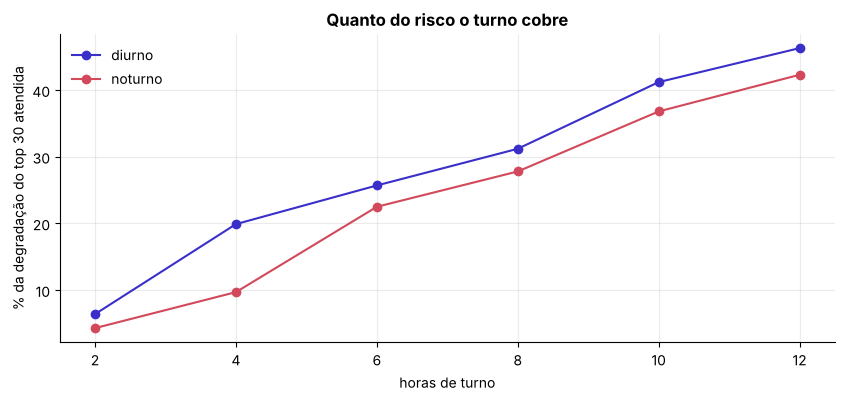

,horas,turno,escadas,deslocamento_min,atendimento_min,%_tempo_em_deslocamento,%_degradacao_top30_coberta
0,2,diurno,1,40.0,70.2,36.3,6.4
1,2,noturno,1,53.0,45.0,54.1,4.3
2,4,diurno,3,84.4,150.0,36.0,19.9
3,4,noturno,2,151.9,86.4,63.7,9.7
4,6,diurno,5,84.4,260.4,24.5,25.7
5,6,noturno,4,151.9,200.4,43.1,22.5
6,8,diurno,8,84.4,383.4,18.0,31.2
7,8,noturno,6,151.9,290.4,34.3,27.8
8,10,diurno,10,84.4,513.6,14.1,41.2
9,10,noturno,9,151.9,443.4,25.5,36.8


In [25]:
sens = []
for h in [2, 4, 6, 8, 10, 12]:
    for nome_t, a in [("diurno", adj), ("noturno", adj_noite)]:
        r = planejar_turno("BASE", h, adj=a, ranking=ranking, cadastro=cadastro)["resumo"]
        sens.append({"horas": h, "turno": nome_t, "escadas": r["escadas_atendidas"], "deslocamento_min": r["deslocamento_min"],
                     "atendimento_min": r["atendimento_min"], "%_tempo_em_deslocamento": r["deslocamento_min"] / max(r["tempo_usado_min"], 1) * 100,
                     "%_degradacao_top30_coberta": r["pct_degradacao_coberta"]})
sens = pd.DataFrame(sens)
fig, ax = plt.subplots(figsize=(10, 4))
for nome_t, cor in [("diurno", COR["memo"]), ("noturno", COR["rec"])]:
    s = sens[sens["turno"] == nome_t]; ax.plot(s["horas"], s["%_degradacao_top30_coberta"], "o-", color=cor, label=nome_t)
ax.set(xlabel="horas de turno", ylabel="% da degradação do top 30 atendida", title="Quanto do risco o turno cobre"); ax.legend(frameon=False)
plt.show()
sens.round(1)

**Interpretação — plano do turno:**
- **Turno diurno de 6 h:** a equipe sai da base, vai direto à **escada nº 1 do ranking (REP-ER59)** e passa à nº 2 (LUZ-ER11, a 3 min de metrô).
  Já em Luz, atende **mais três escadas do top 30 da mesma estação** sem novo deslocamento. São 5 escadas, 84 min de deslocamento (24% do turno),
  retorno garantido às 13h44 e **~26% da degradação do top 30** atendida.
- **Turno noturno de 6 h:** com o metrô fechado, o mesmo roteiro custa **152 min de viatura (43% do turno)** e cabem 4 escadas.
  A noite é o horário sem passageiros, mas o deslocamento consome quase metade do tempo.
- **Coerência com os dados:** as checagens automáticas confirmam que o plano cabe nas horas, que os deslocamentos seguem a ordem de criticidade,
  que a escada mais crítica é a primeira e que não há repetição. O tempo de cada atendimento vem da mediana real de reparos de cada escada.
- **Sensibilidade:** mesmo 12 h de turno cobrem menos da metade da degradação do top 30, e boa parte do tempo vai para atravessar a linha.
  **🔧 Hipótese para validação:** duas equipes por turno, uma no trecho norte (Luz–Paulista) e outra no sul (Pinheiros–Vila Sônia, perto da base),
  cobririam mais risco com menos deslocamento. Basta chamar `planejar_turno` com bases diferentes para testar.

## 6. Análise de desempenho e conclusões

In [26]:
pd.DataFrame([
    {"algoritmo": "Degradação — recursiva pura", "complexidade tempo": "O(φⁿ) ≈ O(1,618ⁿ)", "memória": "O(n) pilha", "observado": f"{bench['recursiva_ms'].iloc[-1]:,.0f} ms para n={bench.index[-1]}; inviável para 45 meses"},
    {"algoritmo": "Degradação — memoização (dict)", "complexidade tempo": "O(n)", "memória": "O(n) dict + O(n) pilha", "observado": f"{bench['memo_ms'].iloc[-1]:.3f} ms para n={bench.index[-1]}; quebra com n ≳ 1.000 (pilha)"},
    {"algoritmo": "Degradação — tabulação", "complexidade tempo": "O(n)", "memória": "O(n) (O(1) possível guardando só 2 valores)", "observado": f"{bench['tabulacao_ms'].iloc[-1]:.3f} ms para n={bench.index[-1]}; escala até 100 mil leituras"},
    {"algoritmo": "BFS", "complexidade tempo": "O(V + E)", "memória": "O(V)", "observado": "menor nº de trechos, ignora minutos"},
    {"algoritmo": "Dijkstra (heap)", "complexidade tempo": "O((V + E) log V)", "memória": "O(V)", "observado": "menor tempo; base do planejar_turno"},
    {"algoritmo": "A* (linha reta/v_máx + custo fixo)", "complexidade tempo": "≤ Dijkstra (mesmo pior caso)", "memória": "O(V)", "observado": f"mesmo ótimo; {esc.loc[('noturna', 3600), 'redução_expansões_completa_%']:.0f}% menos expansões na malha noturna de 3.600 vértices"},
    {"algoritmo": "planejar_turno", "complexidade tempo": "O(K · (V+E) log V + K²)", "memória": "O(K·V)", "observado": "K = 30 candidatas; Dijkstra em cache por estação visitada"},
]).set_index("algoritmo")

,complexidade tempo,memória,observado
algoritmo,,,
Degradação — recursiva pura,"O(φⁿ) ≈ O(1,618ⁿ)",O(n) pilha,94 ms para n=28; inviável para 45 meses
Degradação — memoização (dict),O(n),O(n) dict + O(n) pilha,0.006 ms para n=28; quebra com n ≳ 1.000 (pilha)
Degradação — tabulação,O(n),O(n) (O(1) possível guardando só 2 valores),0.002 ms para n=28; escala até 100 mil leituras
BFS,O(V + E),O(V),"menor nº de trechos, ignora minutos"
Dijkstra (heap),O((V + E) log V),O(V),menor tempo; base do planejar_turno
A* (linha reta/v_máx + custo fixo),≤ Dijkstra (mesmo pior caso),O(V),mesmo ótimo; 58% menos expansões na malha noturna de 3.600 vértices
planejar_turno,O(K · (V+E) log V + K²),O(K·V),K = 30 candidatas; Dijkstra em cache por estação visitada


### Conclusões
1. A **degradação acumulada** com memória de dois meses, estimada nos dados reais da ViaQuatro, transforma o histórico de falhas em um **índice de condição atual** por escada, explicável por família de sinal.
2. A **programação dinâmica** é o que torna o cálculo viável: a mesma recorrência que levaria ~17 h na versão recursiva pura roda em milissegundos com tabulação, sem limite de pilha.
3. Na rede de estações, **Dijkstra** é o critério certo para o técnico (até 40% menos tempo que o caminho com menos trechos). O **A\*** mantém o ótimo e só compensa em redes maiores ou no turno noturno, quando a heurística é justa.
4. `planejar_turno(base, horas)` junta tudo: **ranking (PD) + rotas (Dijkstra) + tempos reais de reparo**, priorizando sempre a escada mais crítica e aproveitando cada viagem.

**Próximos passos:** substituir as ocorrências mensais por leituras reais de sensores (mesmo formato de CSV), incluir o grupo de criticidade (Crítica A/B) como peso adicional e testar múltiplas equipes/bases.